# Scientific Programming (MSB1015) Course Project Data Overview

## Data Prepraration including Quality Control for Sessions, Probes, Channels and Units

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from paths import EXTRACTED_DIR, MANIFEST
import os, glob, shutil, gc, time

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache # API for Allen Natural Movies data

c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Constants

In [2]:
# Areas of interest in the visual cortex, for filtering units to just those regions.
VISUAL_CORTEX = ["VISp", "VISl", "VISal", "VISrl", "VISam", "VISpm"]  # the identifiers for the regions of the visual cortex in the Allen Natural Movies dataset

# taken from https://allensdk.readthedocs.io/en/latest/visual_coding_neuropixels.html
ALLEN_DEFAULTS = dict(
    amplitude_cutoff_maximum=0.1,
    presence_ratio_minimum=0.95,
    isi_violations_maximum=0.5,
)

# custom quality control thresholds for Allen Natural Movies dataset, stricter than Allen's defaults
CUSTOM_THRESHOLDS = dict(
    isi_violations_maximum=0.1,     # tighter than Allen's 0.5 → cleaner units
    amplitude_cutoff_maximum=0.1,
    presence_ratio_minimum=0.95,
    firing_rate_minimum=0.1,        # drops near-silent units (no decodable signal)
    snr_minimum=1.0,                # optional snr threshold to drop overly noisy units (no decodable signal)
)

REFRACTORY_S = 0.0015               # 1.5ms refractory time of neurons, ISIs can't be shorter (biological minimum)
 
# Neuropixels 1.0 hardware specifications (for probe/channel sanity checks).
EXPECTED_AP_RATE = 30000           # Hz, action-potential band
EXPECTED_LFP_RATE = 1250           # Hz, LFP band (≈ 2500/2 see https://allensdk.readthedocs.io/en/2.16.0/_static/examples/nb/ecephys_lfp_analysis.html the variable "lfp_sampling_rate")
EXPECTED_CHANNELS_PER_PROBE = 384  # Neuropixels 1.0 has 384 channels https://doi.org/10.1038/nature24636

# For Data Extraction
MOVIE        = "natural_movie_one"    # more repeats than natural_movie_three
BIN_SIZE     = 0.01                   # 10 ms, fine-grained enough for any Δ window later
MAX_SESSIONS = None                   # None for all, small value for testing (e.g., 2 or 3)

# Okabe-Ito colorblind-friendly palette
REGION_COLORS = {"VISp": "#0072B2", "VISl": "#E69F00", "VISal": "#009E73",
                 "VISrl": "#D55E00", "VISam": "#CC79A7", "VISpm": "#56B4E9"}
KEEP_GREY = "#C7CED6"   # neutral grey for removed caps / ghosts
CUT_RED   = "#D55E00"   # for the mass that a custom threshold removes
INK       = "#1F2933"

## Helper Functions for better readability of outputs

In [3]:
def _header(title: str) -> None:
    """
    Prints a header for a section.
    """
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)
 
 
def _check(label: str, ok: bool, detail: str = "") -> bool:
    """
    Prints the result of a sanity check, with a label and optional detail.
    """
    mark = "PASS" if ok else "WARN"
    line = f"  [{mark}] {label}"
    if detail:
        line += f":  {detail}"
    print(line)
    return ok
 
 
def _col(df: pd.DataFrame, *candidates: str) -> str | None:
    """
    Returns the first column name that exists (API names drift across versions).
    """
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    return None

## Sessions

In [4]:
def qc_sessions(cache: EcephysProjectCache) -> pd.DataFrame:
    """
    Sanity-check for the session table and subsequent selection of suitable sessions.
 
    Verifies Allen's quality control (session types, per-session counts, that the
    natural movies actually exist where they should) and returns the subset of
    sessions to keep: sessions with type brain_observatory_1.1 with units 
    in the areas of interest (visual cortex areas).
    """
    _header("SESSIONS: sanity checks on Allen's session table")
    sessions = cache.get_session_table()  # gets session metadata

    # checks whether metadata is present at all
    _check("session table is non-empty", len(sessions) > 0, f"{len(sessions)} sessions")
 
    # session_type: checks for exactly the two documented types
    st_col = _col(sessions, "session_type")  # extract the session_type column (API names drift across versions)
    types = sessions[st_col].value_counts()  # counts how many sessions of each type exist
    # prints out the check for the session types
    print("\n  session_type breakdown:")
    for typ, n in types.items():
        print(f"      {typ:<28} {n}")
    expected = {"brain_observatory_1.1", "functional_connectivity"}
    _check("only documented session types present", set(types.index) <= expected,
           f"unexpected: {set(types.index) - expected}" if set(types.index) - expected else "ok")
 
    # checks whether per-session count columns are present, positive, and consistent
    for count_col in ["unit_count", "channel_count", "probe_count"]:
        col = _col(sessions, count_col)
        if col:
            _check(f"'{count_col}' present and > 0 for all sessions",
                   bool((sessions[col] > 0).all()),
                   f"min={sessions[col].min()}, max={sessions[col].max()}")
 
    # checks that probe_count should never exceed 6, as the Neuropixels shank has 6 insertions max
    probe_count = _col(sessions, "probe_count")
    if probe_count:
        _check("probe_count ≤ 6 for every session", bool((sessions[probe_count] <= 6).all()),
               f"max probe_count = {sessions[probe_count].max()}")
 
    # checks that the demographic and genotype fields are populated
    for meta_col in ["sex", "full_genotype", "age_in_days"]:
        col = _col(sessions, meta_col)
        if col:
            n_missing = sessions[col].isna().sum()
            _check(f"'{meta_col}' populated", n_missing == 0, f"{n_missing} missing")
 
    # checks that the natural movies must be declared on brain_observatory sessions
    struct_col = _col(sessions, "ecephys_structure_acronyms")
    if struct_col:
        # every session should report at least one recorded structure
        empty = sessions[struct_col].apply(lambda s: len(s) == 0 if hasattr(s, "__len__") else True).sum()
        _check("every session lists ≥1 recorded structure", empty == 0, f"{empty} empty")
 
    # SELECTS the brain_observatory_1.1 sessions for this task
    keep = sessions[sessions[st_col] == "brain_observatory_1.1"].copy()
    print(f"\n  → keeping {len(keep)} 'brain_observatory_1.1' sessions "
          f"(the natural movies sessions);")
    print(f"     dropping {len(sessions) - len(keep)} 'functional_connectivity' sessions.")
 
    # checks how many of the selected brain_observatory_1.1 sessions actually record from the desired visual cortex areas
    if struct_col:
        has_visual = keep[struct_col].apply(
            lambda s: any(a in VISUAL_CORTEX for a in s) if hasattr(s, "__len__") else False)
        print(f"     {has_visual.sum()} of them record from ≥1 of {VISUAL_CORTEX}.")
        keep = keep[has_visual]
 
    return keep

## Probes

In [5]:
def qc_probes(cache: EcephysProjectCache) -> pd.DataFrame:
    """
    Sanity-check for the probe table: sampling rates, LFP availability, naming,
    and whether every probe is anchored to a real session.
    """
    _header("PROBES: sanity checks on Allen's probe table")
    probes = cache.get_probes()
    _check("probe table is non-empty", len(probes) > 0, f"{len(probes)} probes")
 
    # checks that AP sampling rate should be ~30 kHz
    sr = _col(probes, "sampling_rate")
    if sr:
        near_ap = np.isclose(probes[sr], EXPECTED_AP_RATE, rtol=0.05) # allows 5% tolerance for the AP sampling rate
        _check(f"AP sampling_rate ≈ {EXPECTED_AP_RATE} Hz",
               bool(near_ap.all()),
               f"range {probes[sr].min():.0f}–{probes[sr].max():.0f} Hz") # prints the range of AP sampling rates across all probes
 
    # checks that probe names A–F are unique within each session (for probe naming convention see: https://allensdk.readthedocs.io/en/latest/_static/examples/nb/ecephys_data_access.html)
    sess_col = _col(probes, "ecephys_session_id")
    name_col = _col(probes, "name", "description")
    if sess_col and name_col:
        dup = probes.groupby(sess_col)[name_col].apply(lambda s: s.duplicated().any()).sum()
        _check("probe names unique within each session", dup == 0,
               f"{dup} session(s) with duplicate probe names")
 
    # checks that channel_count per probe is plausible (≤ 384 active sites)
    cc = _col(probes, "channel_count")
    if cc:
        _check(f"channel_count ≤ {EXPECTED_CHANNELS_PER_PROBE} per probe",
               bool((probes[cc] <= EXPECTED_CHANNELS_PER_PROBE + 1).all()),
               f"max = {probes[cc].max()}")
 
    # checks that every probe references an actually existing session
    if sess_col:
        sessions = cache.get_session_table()
        orphan = (~probes[sess_col].isin(sessions.index)).sum()
        _check("every probe maps to a session in the session table", orphan == 0,
               f"{orphan} orphan probe(s)")
 
    return probes

## Channels

In [6]:
def qc_channels(cache: EcephysProjectCache) -> pd.DataFrame:
    """
    Sanity-checks the channel table: CCF registration (assignment to a CCFv3 brain region),
    structure labels, geometry, and how many channels fall outside any brain structure.
    """
    _header("CHANNELS: sanity checks on Allen's channel table & CCF registration")
    channels = cache.get_channels()
    _check("channel table is non-empty", len(channels) > 0, f"{len(channels):,} channels")
 
    # checks that CCF coordinates are present for channels that carry a structure (brain region)
    ap = _col(channels, "anterior_posterior_ccf_coordinate")
    dv = _col(channels, "dorsal_ventral_ccf_coordinate")
    lr = _col(channels, "left_right_ccf_coordinate")
    struct = _col(channels, "ecephys_structure_acronym")
 
    if struct:  # the channel's brain-structure
        n_no_struct = channels[struct].isna().sum()
        _check("structure label present for most channels", True,
               f"{n_no_struct:,} channels ({100*n_no_struct/len(channels):.1f}%) have NO structure "
               f"outside brain / unregistered expected, exclude for region analyses")
 
    if ap and dv and lr and struct:  # ap: anterior–posterio, dv: dorsal–ventral, lr: left–right, all CCF coordinates
        # a channel with a structure label should have valid CCF coordinates
        has_struct = channels[struct].notna()
        # Allen encodes "no coordinate" as NaN or as a negative sentinel (placeholder meaning "no coordinate")
        bad_coord = has_struct & (
            channels[[ap, dv, lr]].isna().any(axis=1) | (channels[[ap, dv, lr]] < 0).any(axis=1))
        _check("structure-labelled channels have valid CCF coordinates",
               bad_coord.sum() == 0,
               f"{bad_coord.sum()} labelled channels with missing/negative coords")
 
    # checks that vertical position is monotonic-ish along the shank (probes are positioned along the shank, so the vertical position should increase along the probe)
    vpos = _col(channels, "probe_vertical_position")
    prb = _col(channels, "ecephys_probe_id")
    if vpos and prb:
        rng = channels.groupby(prb)[vpos].agg(lambda s: s.max() - s.min())
        _check("channels span a physical range along each shank",
               bool((rng > 0).all()), f"median span = {rng.median():.0f} µm")
 
    # checks for optional explicit validity flag
    valid = _col(channels, "valid_data")
    if valid:
        n_invalid = (~channels[valid].astype(bool)).sum()
        _check("valid_data flag present", True,
               f"{n_invalid:,} channels flagged invalid_data (to be dropped)")
 
    # checks the coverage of the target areas from the visual cortex
    if struct:
        cov = channels[channels[struct].isin(VISUAL_CORTEX)][struct].value_counts()
        print("\n  channels per target visual area (dataset-wide):")
        for a in VISUAL_CORTEX:
            print(f"      {a:<7} {int(cov.get(a, 0)):>7,}")
 
    return channels

## Units

In [7]:
def qc_units(cache: EcephysProjectCache) -> pd.DataFrame:
    """
    Sanity-checks the precomputed unit QC metrics and reproduces Allen's default
    filter, then applies the custom thresholds. Returns the selected units for the analysis.
    """
    _header("UNITS: sanity checks on Allen's precomputed QC metrics")
 
    # Pulls the entire data without the Allen preprocessing (defeats the SDK's silent default filter) so the the full distribution can be seen and reproducd by the custom filtering.
    allen = cache.get_units(
        amplitude_cutoff_maximum=np.inf,
        presence_ratio_minimum=-np.inf,
        isi_violations_maximum=np.inf,
        filter_by_validity=False,
    )
    
    allen_selected_units = cache.get_units()  # SDK defaults applied
    print(f"  units in table: {len(allen):,} total  →  {len(allen_selected_units):,} after SDK default filter "
          f"({100*len(allen_selected_units)/len(allen):.1f}% kept)")
 
    # checks that the required metric columns exist
    metrics = ["firing_rate", "presence_ratio", "isi_violations", "amplitude_cutoff",
               "snr", "isolation_distance", "nn_hit_rate", "nn_miss_rate",
               "silhouette_score", "d_prime", "max_drift", "cumulative_drift",
               "waveform_duration"]
    present = [m for m in metrics if m in allen.columns]
    _check("core QC metric columns present", len(present) >= 8,
           f"{len(present)}/{len(metrics)} found")
 
    # checks that metrics live in physically plausible ranges
    def _range_ok(col, lo, hi):
        if col not in allen.columns:
            return
        s = allen[col].dropna()
        ok = bool((s >= lo).all() and (s <= hi).all())
        _check(f"{col} in [{lo}, {hi}]", ok, f"observed {s.min():.3g} … {s.max():.3g}")
 
    _range_ok("presence_ratio", 0.0, 1.0)      # fraction of time the unit is present, [0–1]
    _range_ok("amplitude_cutoff", 0.0, 0.5)    # false-negative rate, fraction of the unit's spikes that were missed, capped at ~0.5 by Allen
    _range_ok("nn_hit_rate", 0.0, 1.0)         # nearest neighbor hit rate, fraction of the unit's spikes that were correctly classified, [0–1]
    _range_ok("nn_miss_rate", 0.0, 1.0)        # nearest neighbor miss rate, fraction of the unit's spikes that were incorrectly classified, [0–1]
    
    # checks whether there are any interspike interval violations
    if "isi_violations" in allen.columns:
        _check("isi_violations ≥ 0", bool((allen["isi_violations"].dropna() >= 0).all()))
    # chcecks whether there are any negative firing rates
    if "firing_rate" in allen.columns:
        _check("firing_rate ≥ 0", bool((allen["firing_rate"].dropna() >= 0).all()),
               f"max = {allen['firing_rate'].max():.1f} Hz")
 
    # reproduces Allen's default filter
    allen_reproduced = allen[
        (allen["amplitude_cutoff"] <= ALLEN_DEFAULTS["amplitude_cutoff_maximum"]) &
        (allen["presence_ratio"]   >= ALLEN_DEFAULTS["presence_ratio_minimum"]) &
        (allen["isi_violations"]   <= ALLEN_DEFAULTS["isi_violations_maximum"])
    ]
    # allows small wiggle room: SDK also drops invalid units (quality == 'noise')
    _check("Tthe SDK default filter can be reproduced(tolerance ±2%)",
           abs(len(allen_reproduced) - len(allen_selected_units)) / max(len(allen_selected_units), 1) < 0.02 + 0.05,
           f"reproduction {len(allen_reproduced):,} vs SDK {len(allen_selected_units):,} "
           f"(difference is the validity/'noise' filter)")
 
    # checks how many units each criterion removes
    print("\n  units removed by each default criterion (of the full table):")
    for name, mask in [
        ("amplitude_cutoff > 0.1", allen["amplitude_cutoff"] > 0.1),
        ("presence_ratio < 0.95",   allen["presence_ratio"] < 0.95),
        ("isi_violations > 0.5",   allen["isi_violations"] > 0.5),
    ]:
        print(f"      {name:<26} {int(mask.sum()):>7,}  ({100*mask.mean():.1f}%)")
 
    # checks region label coverage
    reg = _col(allen_selected_units, "ecephys_structure_acronym")
    if reg:
        n_nan = allen_selected_units[reg].isna().sum()
        _check("region label present on allen_selected_units units", True,
               f"{n_nan:,} allen_selected_units units that have NaN region (to be dropped for per-area analysis)")
 
    # Applies custom thresholds and filters for visual cortex areas, returning the selected units
    keep = allen_selected_units.copy()
    if reg:
        keep = keep[keep[reg].isin(VISUAL_CORTEX)]
    keep = keep[
        (keep["isi_violations"]  <= CUSTOM_THRESHOLDS["isi_violations_maximum"]) &
        (keep["amplitude_cutoff"] <= CUSTOM_THRESHOLDS["amplitude_cutoff_maximum"]) &
        (keep["presence_ratio"]  >= CUSTOM_THRESHOLDS["presence_ratio_minimum"]) &
        (keep["firing_rate"]     >= CUSTOM_THRESHOLDS["firing_rate_minimum"])
    ]
    if "snr" in keep.columns and "snr_minimum" in CUSTOM_THRESHOLDS:
        keep = keep[keep["snr"] >= CUSTOM_THRESHOLDS["snr_minimum"]]
 
    print(f"\n  → after custom thresholds + visual-cortex filter: {len(keep):,} units")
    if reg:
        print("     per area:")
        for a, n in keep[reg].value_counts().reindex(VISUAL_CORTEX).dropna().items():
            print(f"        {a:<7} {int(n):>6,}")
    return keep

## Per-Session internal QC

In [8]:
def qc_session_internal(session) -> dict:
    """
    Performs checks that can only be performed upon loading a session's actual data:
    invalid time windows, stimulus presence, and spike-time integrity.
    `session` is the object from cache.get_session_data(session_id).
    """
    _header(f"SESSION {session.ecephys_session_id}: internal QC (loaded data)")
 
    out = {}
 
    # excludes invalid time intervals Allen flagged
    try:
        inv = session.get_invalid_times()
    except Exception:
        inv = pd.DataFrame()
    out["invalid_times"] = inv
    if len(inv):
        start = _col(inv, "start_time")
        stop = _col(inv, "stop_time")
        dur = (inv[stop] - inv[start]).sum() if start and stop else float("nan")
        _check("invalid_times present: MUST be excluded from trials/spikes",
               True, f"{len(inv)} interval(s), {dur:.1f}s total flagged bad")
    else:
        _check("no invalid_times flagged for this session", True)
 
    # checks that expected natural-movie stimuli are present
    names = list(session.stimulus_names)
    movies = [n for n in names if "natural_movie" in n]
    _check("natural movie stimuli present", len(movies) > 0, f"found: {movies}")
 
    # checks spike-time integrity
    st = session.spike_times                       # {unit_id: np.array}
    all_first = min((s.min() for s in st.values() if len(s)), default=np.nan)
    all_last = max((s.max() for s in st.values() if len(s)), default=np.nan)
    # checks that there are no negative spike times
    _check("no negative spike times", all_first >= 0, f"earliest spike = {all_first:.2f}s")
    # every spiking unit should be monotonically sorted (Allen guarantees this)
    unsorted = sum(1 for s in st.values() if len(s) > 1 and np.any(np.diff(s) < 0))
    _check("spike times monotonically increasing per unit", unsorted == 0,
           f"{unsorted} unit(s) with out-of-order spikes")
    print(f"     recording span ≈ {all_last - all_first:.0f}s, {len(st)} units with spike trains")
 
    # checks for units without a region label
    reg = _col(session.units, "ecephys_structure_acronym")
    if reg:
        n_nan = session.units[reg].isna().sum()
        _check("session units carry region labels", True,
               f"{n_nan} unit(s) with NaN region in this session")
 
    return out
 
 
def verify_unit_metrics(session, n_units: int = 30, seed: int = 0) -> pd.DataFrame:
    """
    Recomputes two metrics from the raw spike times and compares them against Allen's stored values.
      • firing_rate      : n_spikes / (last - first spike)   [Allen's definition]
      • short-ISI fraction: fraction of ISIs below the refractory period, used
        as a proxy that should rank-correlate with Allen's isi_violations.
 
    A high correlation / near-1 ratio confirms the precomputed metrics describe
    the spike trains actually received.
    """
    _header(f"SESSION {session.ecephys_session_id}: VERIFY Allen's unit metrics")
    units = session.units
    spike_times = session.spike_times
    rng = np.random.default_rng(seed)
    ids = rng.choice(units.index.values, size=min(n_units, len(units)), replace=False)
 
    rows = []
    # iterates over all units, building the per-unit quality control table
    for unit_id in ids:
        spikes = np.asarray(spike_times.get(unit_id, np.empty(0, dtype=float)))
        if spikes.size < 2:  # skips unit if it has < 2 spikes (no ISI can be calculated then)
            continue
        duration = spikes[-1] - spikes[0]  # duration obtained by last spike time - first spike time
        firing_rate_recomputed = spikes.size / duration if duration > 0 else np.nan
        isis = np.diff(spikes)        # interspike interval = time between spikes
        short_frac = np.mean(isis < REFRACTORY_S)  # mthe ean of boolean array (0,1) gives the fraction of ISIs below the refractory period
        rows.append(dict(
            unit_id=unit_id,
            firing_rate_allen=units.loc[unit_id, "firing_rate"] if "firing_rate" in units else np.nan,
            firing_rate_recomputed=firing_rate_recomputed,
            isi_allen=units.loc[unit_id, "isi_violations"] if "isi_violations" in units else np.nan,
            short_isi_frac=short_frac,
        ))
    df = pd.DataFrame(rows)
 
    if len(df):
        # checks that firing rates match (almost) exactly
        ratio = (df["firing_rate_recomputed"] / df["firing_rate_allen"]).replace([np.inf, -np.inf], np.nan)
        _check("recomputed firing_rate matches Allen's (ratio ≈ 1)",
               bool(np.nanmedian(ratio.between(0.9, 1.1).astype(float)) == 1.0
                    or np.nanmedian(ratio).round(2) == 1.0),
               f"median ratio = {np.nanmedian(ratio):.3f}")
        # checks that short-ISI fractions rank-correlate with Allen's isi_violations
        corr = df[["short_isi_frac", "isi_allen"]].corr(method="spearman").iloc[0, 1]
        _check("short-ISI fraction rank-correlates with isi_violations",
               (not np.isnan(corr)) and corr > 0.4,
               f"Spearman ρ = {corr:.2f}")
        print("\n  sample (first 8 units):")
        print(df.head(8).to_string(index=False,
              float_format=lambda x: f"{x:.3f}"))
    else:
        _check("enough spiking units to verify", False, "no units with ≥2 spikes sampled")
    return df

## Preprocessing Effects Overview

Generates three figures showing the effects of the quality control which has been added on top of Allen's preprocessing:
- per-region unit selection (before/after)
- the overall unit-attrition funnel
- the QC-metric distributions between Allen defaults vs custom thresholds.

These figures require only `cache.get_units()` (the smaller unit-metadata table) and not the large session NWB-files. The section runs on its own without re-downloading or re-extracting anything (in case one wants to run just them to reproduce).

In [9]:
def qc_stage_tables(cache: EcephysProjectCache) -> dict:
    """
    In one single pass over the cache builds everything the data tables for 3 figures
    giving an overview of the effects of the preprocessing steps performed.
    Mirrors the keep/drop logic of qc_units:
      full table -> Allen default (cache.get_units()) -> + visual cortex
                 -> + ISI<=0.1 -> + firing_rate>=0.1 -> + SNR>=1.0
    """
    # complete, unfiltered table (defeats the SDK's silent default filter)
    full = cache.get_units(amplitude_cutoff_maximum=np.inf,
                           presence_ratio_minimum=-np.inf,
                           isi_violations_maximum=np.inf,
                           filter_by_validity=False)
    allen = cache.get_units()  # SDK defaults applied
    reg = _col(allen, "ecephys_structure_acronym", "structure_acronym")

    # nested filter stages (counts for the funnel figure)
    s_region = allen[allen[reg].isin(VISUAL_CORTEX)] if reg else allen
    s_isi    = s_region[s_region["isi_violations"] <= CUSTOM_THRESHOLDS["isi_violations_maximum"]]
    s_fr     = s_isi[s_isi["firing_rate"] >= CUSTOM_THRESHOLDS["firing_rate_minimum"]]
    s_snr    = s_fr[s_fr["snr"] >= CUSTOM_THRESHOLDS["snr_minimum"]] if "snr" in s_fr else s_fr
    custom   = s_snr  # final retained set

    funnel = [
        ("All units (unfiltered)",        len(full)),
        ("Allen default QC",              len(allen)),
        ("+ Visual Cortex (6 areas)",     len(s_region)),
        (f"+ ISI ≤ {CUSTOM_THRESHOLDS['isi_violations_maximum']}",          len(s_isi)),
        (f"+ Firing rate ≥ {CUSTOM_THRESHOLDS['firing_rate_minimum']} Hz",  len(s_fr)),
        (f"+ SNR ≥ {CUSTOM_THRESHOLDS['snr_minimum']}",                     len(s_snr)),
    ]

    allen_default = (s_region[reg].value_counts().reindex(VISUAL_CORTEX).fillna(0).astype(int)
              if reg else pd.Series(dtype=int))  # Allen-default, per area
    custom_qc  = (custom[reg].value_counts().reindex(VISUAL_CORTEX).fillna(0).astype(int)
              if reg else pd.Series(dtype=int))  # custom QC, per area

    hist_pop = full[full[reg].isin(VISUAL_CORTEX)] if reg else full  # for the histograms

    return dict(funnel=funnel, before=allen_default, after=custom_qc,
                hist_pop=hist_pop, n_all=len(full))

In [10]:
def plot_region_before_after(stages: dict, save: str | None = None):
    """
    Figure 1:
    Per-region unit selection, before and after the custom QC.
        - 1 Stacked bar per region: solid base = units kept by custom QC (area colour)
        - hatched grey cap: units the custom QC removes.
        - full bar: Allen-default count.
    """
    regions = VISUAL_CORTEX
    before  = stages["before"].reindex(regions).fillna(0).astype(int)  # allen default
    after   = stages["after"].reindex(regions).fillna(0).astype(int)   # custom qc
    removed = (before - after).clip(lower=0)

    fig, ax = plt.subplots(figsize=(9, 5.2))
    # iterates over the regions and plots the stacked bars for each region, showing the number of units kept and removed by the custom QC
    for i, r in enumerate(regions):
        c = REGION_COLORS.get(r, "#777777")

        ax.bar(i, after[r], color=c, width=0.64, zorder=3)
        # plots the number of units removed by the custom QC as a hatched grey cap on top of the kept units
        ax.bar(i, removed[r], bottom=after[r], width=0.64, zorder=3,
               facecolor=KEEP_GREY, edgecolor="white", hatch="///", linewidth=0)
        # percentage of units kept after custom QC relative to Allen default
        pct = 100 * after[r] / before[r] if before[r] else 0

        ax.text(i, after[r] / 2, f"{after[r]:,}", ha="center", va="center",
                color="white", fontsize=9, fontweight="bold", zorder=4)
        ax.text(i, before[r] + (before.max() or 1) * 0.015, f"{pct:.0f}% kept",
                ha="center", va="bottom", color=INK, fontsize=9)

    ax.set_xticks(range(len(regions)))
    ax.set_xticklabels(regions, fontsize=11)
    ax.set_ylabel("units", fontsize=11)
    ax.set_title("Unit selection per region: before vs after custom QC", fontsize=13, pad=14)
    ax.set_ylim(0, (before.max() or 1) * 1.14)

    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", alpha=0.18, zorder=0)
    ax.legend(handles=[Patch(facecolor="#6B7B8C", label="retained for analysis (area colour)"),
                       Patch(facecolor=KEEP_GREY, hatch="///", label="removed by custom QC")],
              frameon=False, fontsize=9, loc="upper right")
    fig.tight_layout()
    
    if save:
        fig.savefig(save, dpi=150, bbox_inches="tight")
        print(f"  saved {save}")
    else:
        plt.show()
    return fig

In [11]:
def plot_attrition_funnel(stages: dict, save: str | None = None):
    """
    Figure 2:
    Plots the unit attrition through the extended preprocessing pipeline.
    Horizontal funnel: each stage's solid bar represents the surviving units,
    the grey ghosts represent the previous stage (grey sliver = removed at that step)
    Right labels: count, % of all units, and the step delta.
    """
    funnel = stages["funnel"]  # contains the funnel specifications: list of tuples (label, count)
    labels, counts = zip(*funnel)  # labels for the y-axis, counts for each stage
    n_all  = counts[0]
    y = np.arange(len(counts))[::-1]  # top row = "All units"

    fig, ax = plt.subplots(figsize=(10, 5.4))
    # iterates over the funnel stages and plots the horizontal bars for each stage, showing the number of surviving units and the number removed at each step
    for i, n in enumerate(counts):
        y_i = y[i]
        prev = counts[i - 1] if i > 0 else n  # unit count of the previous stage (for the first stage, prev = n)

        ax.barh(y_i, prev, color=KEEP_GREY, height=0.62, zorder=2)  # ghosts of previous stage
        ax.barh(y_i, n, color="#0072B2", height=0.62, zorder=3)   # survivors

        delta = f"  (−{prev - n:,})" if i > 0 and prev - n > 0 else ""
        ax.text(n_all * 1.01, y_i, f"{n:,}   {100*n/n_all:4.1f}%{delta}",
                va="center", ha="left", fontsize=9.5, color=INK)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels[::-1], fontsize=10)
    ax.set_xlabel("units", fontsize=11)
    ax.set_title("Unit attrition through the extended preprocessing pipeline", fontsize=13, pad=12)
    ax.set_xlim(0, n_all * 1.15)

    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(left=False)
    ax.grid(axis="x", alpha=0.15, zorder=0)
    ax.legend(handles=[Patch(facecolor="#0072B2", label="surviving"),
                       Patch(facecolor=KEEP_GREY, label="removed at this step")],
              frameon=False, fontsize=9, loc="center", bbox_to_anchor=(0.58, 0.34))
    
    fig.tight_layout()

    # saves the figure to the specified path if provided, otherwise displays it interactively
    if save:
        fig.savefig(save, dpi=150, bbox_inches="tight")
        print(f"  saved {save}")
    else:
        plt.show()
    return fig

In [12]:
def plot_threshold_distributions(stages: dict, save: str | None = None):
    """
    Figure 3
    QC-metric distributions with Allen vs custom thresholds.
    Histograms of the metrics driving keep/drop. Each with the custom threshold 
    (solid color) and the Allen QC (dashed grey). Shaded vermillion represents the
    mass the custom cut removes. The Population is all units in the 6 areas
    (unfiltered), so both Allen's cut and the extra custom cut are visible (see the ISI panel).
    """
    hist_pop = stages["hist_pop"]  # histogram population: all units in the 6 visual areas (unfiltered)
    A, C = ALLEN_DEFAULTS, CUSTOM_THRESHOLDS  # for better readability

    # specifies one tuple per panel
    # (name, side, allen thr, custom thr, label, log10?)
    # name: name of filtering metric (column in the units table)
    # side: "max" or "min" (whether the threshold is a maximum or minimum)
    # allen thr: Allen's default threshold for that metric
    # custom thr: custom threshold for that metric
    # label: label for the panel
    # log10?: whether to plot the metric on a log10 scale (True for firing rate, False for the others)
    specs = [
        ("isi_violations",   "max", A.get("isi_violations_maximum"),   C.get("isi_violations_maximum"),   "ISI violations",   False),
        ("amplitude_cutoff", "max", A.get("amplitude_cutoff_maximum"), C.get("amplitude_cutoff_maximum"), "Amplitude cutoff", False),
        ("presence_ratio",   "min", A.get("presence_ratio_minimum"),   C.get("presence_ratio_minimum"),   "Presence ratio",   False),
        ("firing_rate",      "min", None,                              C.get("firing_rate_minimum"),      "Firing rate (Hz)", True),
        ("snr",              "min", None,                              C.get("snr_minimum"),              "SNR",              False),
    ]
    specs = [s for s in specs if s[0] in hist_pop.columns]  # drops any metric whose column isn't actually in the table

    # figure with 2×3 grid = six panels (5 metrics + 1 empty for legend)
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5)); axes = axes.ravel()

    # looping where each panel ax is paired with its metric spec
    for ax, (col, side, allen_threshold, custom_threshold, label, use_log) in zip(axes, specs):
        orig = hist_pop[col].replace([np.inf, -np.inf], np.nan).dropna()  # metric's values in original units, with infinities turned to NaN and NaNs dropped
        n_0 = len(orig)  # number of finite units
        data = np.log10(orig[orig > 0]) if use_log else orig  # log10-scales data if specified, otherwise original values

        custom_threshold_line = (np.log10(custom_threshold) if use_log else custom_threshold) if custom_threshold else None
        allen_threshold_line = (np.log10(allen_threshold) if use_log else allen_threshold) if allen_threshold else None

        if use_log:
            label = f"log10 {label}"

        ax.hist(data, bins=60, color="#8FA8BF", alpha=0.9, zorder=2)
        ymax = ax.get_ylim()[1]

        # shades what the custom cut shaves off
        if side == "max":
            removed = int((orig > custom_threshold).sum())
            ax.axvspan(custom_threshold_line, data.max(), color=CUT_RED, alpha=0.14, zorder=1)
        else:
            removed = int((orig < custom_threshold).sum())
            ax.axvspan(data.min(), custom_threshold_line, color=CUT_RED, alpha=0.14, zorder=1)

        if allen_threshold_line is not None and not np.isclose(allen_threshold_line, custom_threshold_line):     # shows Allen line only when tightened
            ax.axvline(allen_threshold_line, color="#7A7A7A", ls="--", lw=1.6, zorder=4)
            ax.text(allen_threshold_line, ymax * 0.97, f" Allen {allen_threshold:g}", color="#5A5A5A", fontsize=8, ha="left", va="top")

        # plots custom threshold line and label
        ax.axvline(custom_threshold_line, color=INK, lw=2.0, zorder=5)
        same = (allen_threshold is not None and np.isclose(allen_threshold, custom_threshold))

        ax.text(custom_threshold_line, ymax * 0.88, (" custom = Allen" if same else f" custom {custom_threshold:g}"),
                color=INK, fontsize=8.5, ha="left", va="top", fontweight="bold")
        ax.set_title(f"{label}   — removes {removed:,} ({100*removed/n_0:.1f}%)", fontsize=10.5)
        ax.grid(alpha=0.15, zorder=0)

        for s in ("top", "right"):
            ax.spines[s].set_visible(False)

    # blanks out the legend panel
    for ax in axes[len(specs):]:
        ax.axis("off")

    # manually builds panel in the blanked out 6th panel 
    axes[-1].legend(handles=[
        Patch(facecolor="#8FA8BF", label="unit QC-metric distribution"),
        Patch(facecolor=CUT_RED, alpha=0.14, label="removed by custom threshold"),
        plt.Line2D([0], [0], color=INK, lw=2, label="custom threshold"),
        plt.Line2D([0], [0], color="#7A7A7A", lw=1.6, ls="--", label="Allen default (when tightened)"),
    ], frameon=False, fontsize=9.5, loc="center")

    fig.suptitle("QC-metric distributions with Allen vs custom thresholds "
                 "(population: all units in the 6 visual areas)", fontsize=12.5)
    
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    # saves the figure
    if save:
        fig.savefig(save, dpi=150, bbox_inches="tight"); print(f"  saved {save}")
    else:
        plt.show()
    return fig

## Run 3-figure visualization
Renders the 3 extended-preprocessing figures

  saved figs/qc_region_before_after.png
  saved figs/qc_attrition_funnel.png
  saved figs/qc_threshold_distributions.png


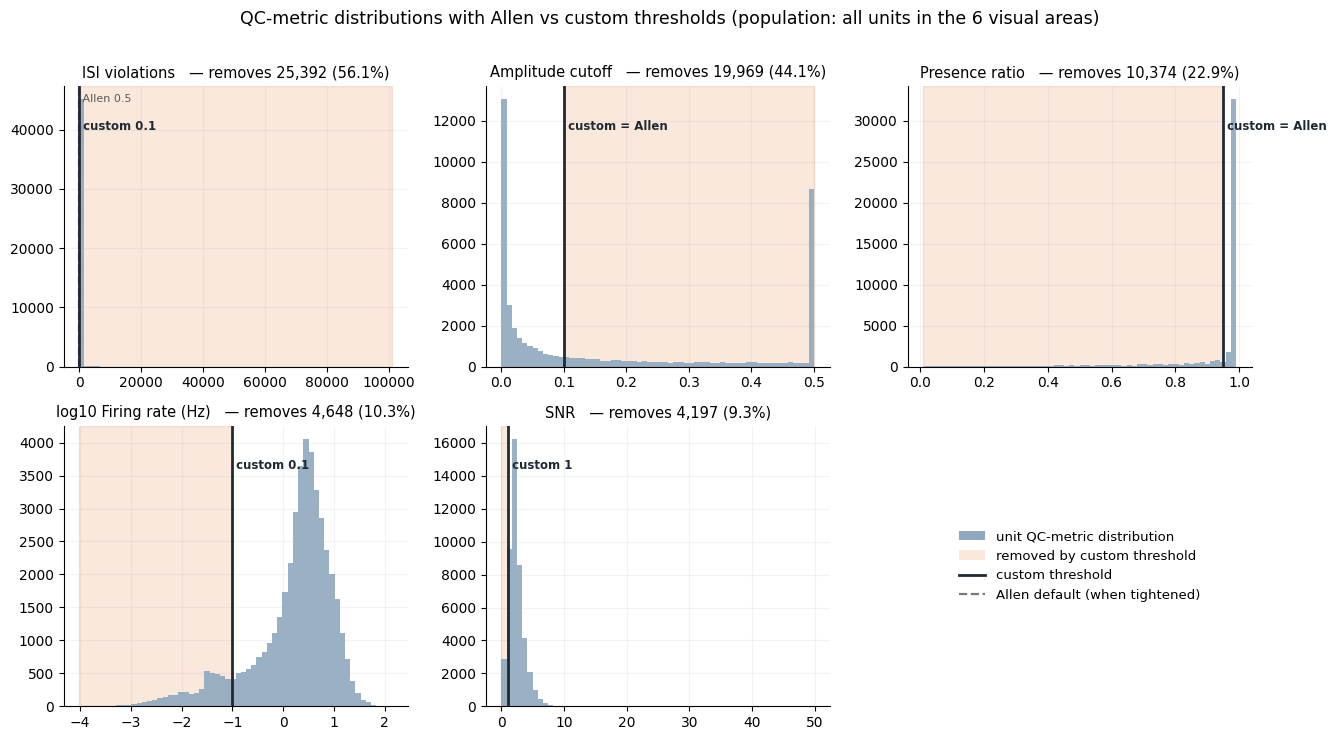

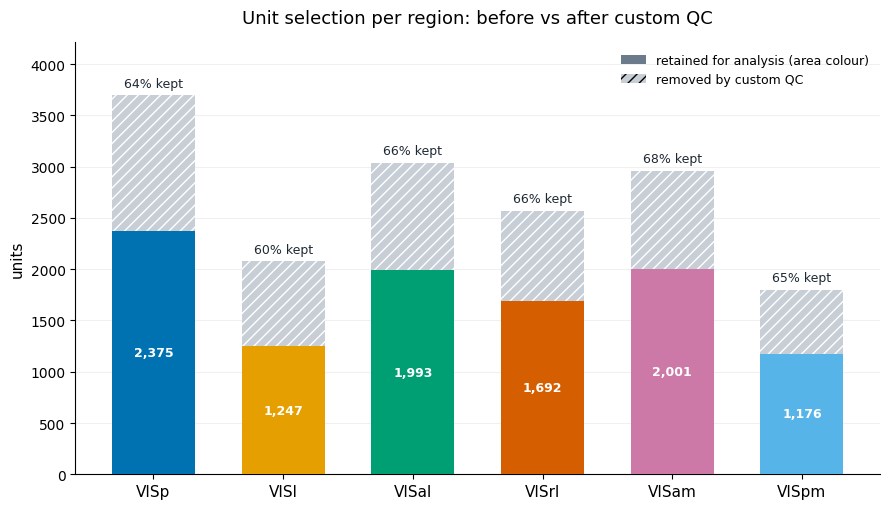

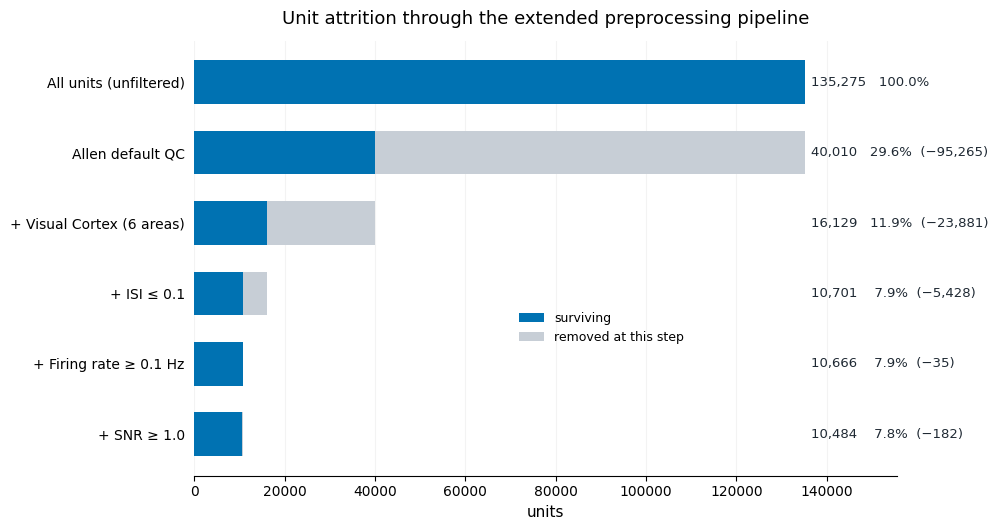

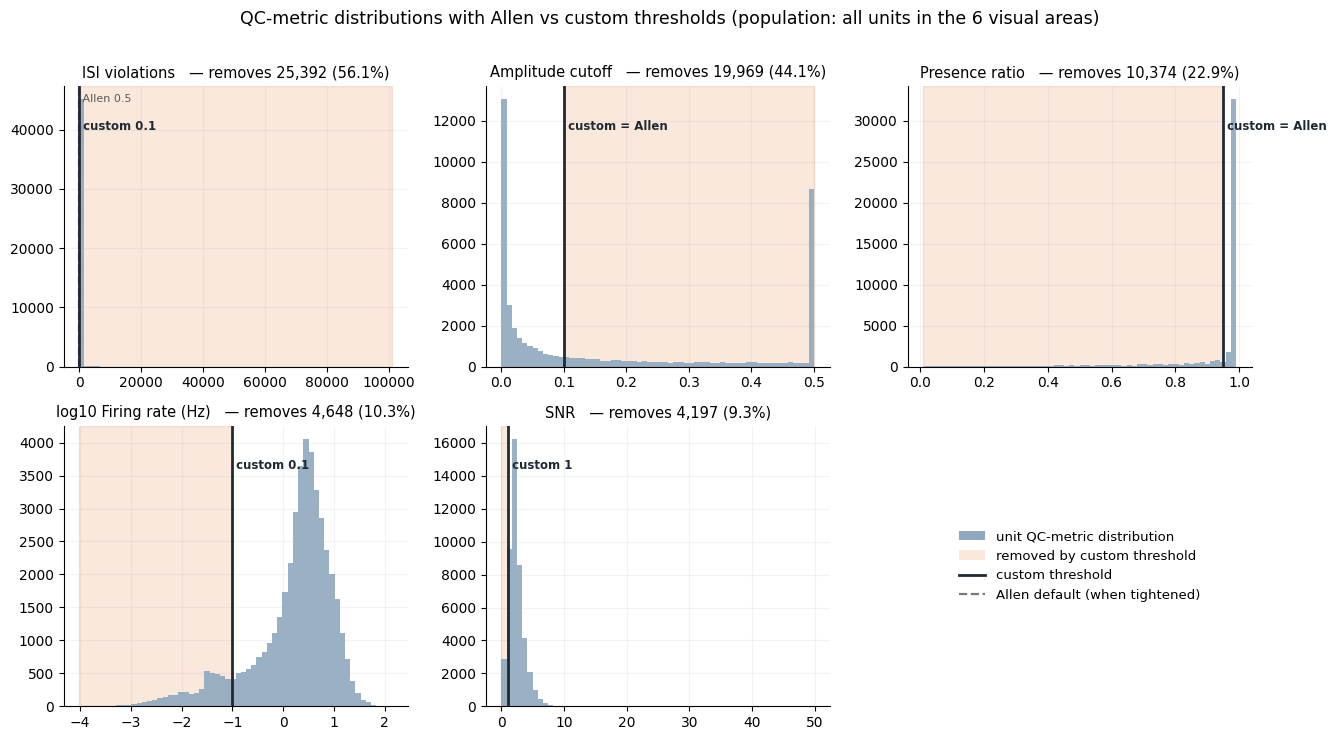

In [13]:
# Needs only cache.get_units() (not the large session NWB-files)
if "cache" not in globals():
    cache = EcephysProjectCache.from_warehouse(manifest=str(MANIFEST))

# makes sure the figure directory exists
FIG_DIR = "figs"
os.makedirs(FIG_DIR, exist_ok=True)

stages = qc_stage_tables(cache)
# Figure 1: per-region unit selection, before and after the custom QC
plot_region_before_after(stages,     save=f"{FIG_DIR}/qc_region_before_after.png")
# Figure 2: unit attrition through the extended preprocessing pipeline
plot_attrition_funnel(stages,        save=f"{FIG_DIR}/qc_attrition_funnel.png")
# Figure 3: QC-metric distributions with Allen vs custom thresholds
plot_threshold_distributions(stages, save=f"{FIG_DIR}/qc_threshold_distributions.png")

## Streaming extraction & discard (one session at a time)

The table-level checks above (`qc_sessions/probes/channels/units`) run on the
cache's small metadata tables → no big downloads. <br>
Only `get_session_data` pulls a session's NWB (a couple of GB; LFP is not downloaded here as it lives in separate per-probe files fetched only by `get_lfp_data`, which never gets called).

So the workflow below is:
<ol>
<li>download one session</li>
<li>internal QC</li>
<li>extracttion of a small feature file</li>
<li>deletion of large NWB file</li>
<li>dowload of next session (go back to 1.)</li>
</ol> 
→ Peak disk use stays at ~one NWB.

What gets extracted is task-agnostic: the whole-movie population
raster per repeat looks like `counts[repeat, time_bin, unit]` at a fine bin, plus each unit's region.<br> 
From this single file any downstream analysis can be performed (segment classification, frame decoding, which-classification) to choose the accumulation windows Δ for the integration-window analysis, without re-downloading.

### Helpers: per-session unit selection & movie-tensor extraction

In [14]:
def select_session_units(session) -> pd.DataFrame:
    """
    Re-applies CUSTOM_THRESHOLDS + visual-cortex filter to just session-specific units
    (same logic as qc_units, but on session.units so extraction is self-contained).
    """
    units = session.units.copy()
    reg = _col(units, "ecephys_structure_acronym")
    if reg:
        units = units[units[reg].isin(VISUAL_CORTEX)]
    units = units[
        (units["isi_violations"]   <= CUSTOM_THRESHOLDS["isi_violations_maximum"]) &
        (units["amplitude_cutoff"] <= CUSTOM_THRESHOLDS["amplitude_cutoff_maximum"]) &
        (units["presence_ratio"]   >= CUSTOM_THRESHOLDS["presence_ratio_minimum"]) &
        (units["firing_rate"]      >= CUSTOM_THRESHOLDS["firing_rate_minimum"])
    ]
    if "snr" in units.columns and "snr_minimum" in CUSTOM_THRESHOLDS:
        units = units[units["snr"] >= CUSTOM_THRESHOLDS["snr_minimum"]]
    return units


def extract_movie_tensor(session, unit_ids, movie: str = "natural_movie_one",
                         bin_size: float = 0.01, fps: float = 30.0):
    """
    Builds the whole-movie neuron population raster, with one continuous time axis per repeat.

    Returns
        counts     : int16 array [n_repeats, n_bins, n_units]  (spike counts/bin)
        unit_ids   : the unit ids in the tensor's 3rd axis order
        bin_starts : bin start offsets (s) relative to each repeat's onset
        onsets     : absolute start time (s) of each repeat

    Repeats are detected as rows where the movie's frame counter resets to its
    minimum (frame 0). Binning is done directly from spike_times via searchsorted
    (transparent, and independent of any SDK binning internals).
    """
    spike_times = session.spike_times                      # {unit_id: sorted np.array}
    presentations = session.stimulus_presentations
    presentations = presentations[presentations["stimulus_name"] == movie].copy().sort_values("start_time")

    # finds beginning of each repeat by looking for the minimum frame number (frame 0) in the stimulus presentations
    f_col = _col(presentations, "frame")
    if f_col is None:
        raise ValueError(f"no 'frame' column for '{movie}': cannot find repeats")
    fmin = presentations[f_col].min()
    # every row where frame == fmin (fmin is normally 0) marks the start of a fresh repeat
    onsets = presentations.loc[presentations[f_col] == fmin, "start_time"].to_numpy()  # is the array of absolute seconds into the session at which each repeat of the movie started (1 entry per repeat)
    if len(onsets) == 0:
        raise ValueError(f"no repeats found for '{movie}'")

    # finds movie repeat length: median gap between consecutive onsets (robust to a trailing
    # partial repeat); fall back to n_frames / fps if only one repeat exists.
    if len(onsets) > 1:
        # yields median gaps between consecutive repeat starts
        rep_dur = float(np.median(np.diff(onsets)))
    else:
        rep_dur = (float(presentations[f_col].max()) - float(fmin) + 1) / fps
    n_bins = int(np.floor(rep_dur / bin_size))
    offsets = np.arange(n_bins + 1) * bin_size  # edges, relative to onset

    unit_ids = np.asarray(unit_ids)
    counts = np.zeros((len(onsets), n_bins, len(unit_ids)), dtype=np.int16)
    for j, unit_id in enumerate(unit_ids):
        spikes = np.asarray(spike_times.get(unit_id, np.empty(0, dtype=float)))
        if spikes.size == 0:
            continue
        for i, t_0 in enumerate(onsets):
            idx = np.searchsorted(spikes, t_0 + offsets)  # cumulative counts at edges
            counts[i, :, j] = np.diff(idx)

    return counts, unit_ids, offsets[:-1], onsets

### Driver: loop, extract, discard

In [15]:
def process_all(cache: EcephysProjectCache, session_ids, out_dir: str,
                movie: str = "natural_movie_one", bin_size: float = 0.01,
                run_internal_qc: bool = True, cleanup: bool = True) -> pd.DataFrame:
    """
    Downloads each session, performs QC the session, extracts the movie tensor,
    saves a small .npz, then deletes the downloaded NWB to reclaim disk space.
    Sessions whose .npz already exists are skipped.
    A session that fails is logged and skipped instead of aborting the whole run.
    """
    os.makedirs(out_dir, exist_ok=True)
    cache_root = os.path.dirname(os.path.abspath(cache.manifest_path))
    summary = []

    # iterates over sessions
    for session_id in session_ids:
        out_path = os.path.join(out_dir, f"session_{session_id}.npz")  # path where the session data is to be stored
        if os.path.exists(out_path):
            print(f"skip session {session_id} (already extracted)")
            continue

        session = None
        try:
            print(f"\n### session {session_id}: downloading NWB (spikes+stimulus, no LFP)...")
            session = cache.get_session_data(session_id)

            # runs internal quality control
            if run_internal_qc:
                qc_session_internal(session)
                verify_unit_metrics(session, n_units=30)

            if movie not in session.stimulus_names:
                print(f"  '{movie}' not shown in this session → skipping extraction")
            else:
                units = select_session_units(session)
                col_name = _col(units, "ecephys_structure_acronym")
                counts, unit_ids, bin_starts, onsets = extract_movie_tensor(
                    session, units.index.values, movie, bin_size)
                np.savez_compressed(
                    out_path,
                    counts=counts,  # [rep, bin, unit] int16
                    unit_ids=unit_ids,
                    regions=units[col_name].to_numpy() if col_name else np.array([]),
                    bin_starts=bin_starts, bin_size=bin_size,
                    onsets=onsets, session_id=session_id, movie=movie,
                )
                mb = os.path.getsize(out_path) / 1e6  # size in megabytes
                print(f"  saved counts{counts.shape} (rep, bin, unit) -> "
                      f"{out_path}  [{mb:.1f} MB]")
                # append to summary list
                summary.append(dict(session_id=session_id, n_repeats=counts.shape[0],
                                    n_bins=counts.shape[1], n_units=counts.shape[2],
                                    file_mb=round(mb, 1), error=None))

        except Exception as e:
            # logs the error and moves on to the next session instead of aborting the whole run
            print(f"  !! session {session_id} FAILED ({type(e).__name__}: {e}) — skipping")
            # a half-written .npz would otherwise be mistaken for 'done' on re-run
            if os.path.exists(out_path):
                os.remove(out_path)
            summary.append(dict(session_id=session_id, n_repeats=None, n_bins=None,
                                n_units=None, file_mb=None,
                                error=f"{type(e).__name__}: {e}"))

        finally:
            if session is not None:
                # best-effort close of the underlying NWB/HDF5 handle
                api = getattr(session, "api", None)
                if api is not None and hasattr(api, "close"):
                    try:
                        api.close()
                    except Exception:
                        pass
                del session
            gc.collect()
            if cleanup:
                for p in glob.glob(os.path.join(cache_root, f"session_{session_id}")):
                    removed = False
                    for _ in range(3):
                        try:
                            shutil.rmtree(p)        # NOT ignore_errors
                            removed = True
                            break
                        except Exception:
                            gc.collect()
                            time.sleep(1.0)
                    print(f"  {'removed' if removed else '!! STILL LOCKED, delete manually'} {p}")

    return pd.DataFrame(summary)

## Running session-wise QC

In [16]:
cache = EcephysProjectCache.from_warehouse(manifest=str(MANIFEST))

# cheap: metadata-only selection of brain_observatory_1.1 sessions in the visual cortex areas
keep_sessions = qc_sessions(cache)
session_ids = keep_sessions.index.tolist()
if MAX_SESSIONS is not None:
    session_ids = session_ids[:MAX_SESSIONS]

summary = process_all(cache, session_ids, out_dir=str(EXTRACTED_DIR),
                      movie=MOVIE, bin_size=BIN_SIZE,
                      run_internal_qc=True, cleanup=True)
print(summary)



SESSIONS: sanity checks on Allen's session table
  [PASS] session table is non-empty:  58 sessions

  session_type breakdown:
      brain_observatory_1.1        32
      functional_connectivity      26
  [PASS] only documented session types present:  ok
  [PASS] 'unit_count' present and > 0 for all sessions:  min=415, max=1005
  [PASS] 'channel_count' present and > 0 for all sessions:  min=1486, max=2298
  [PASS] 'probe_count' present and > 0 for all sessions:  min=4, max=6
  [PASS] probe_count ≤ 6 for every session:  max probe_count = 6
  [PASS] 'sex' populated:  0 missing
  [PASS] 'full_genotype' populated:  0 missing
  [PASS] 'age_in_days' populated:  0 missing
  [PASS] every session lists ≥1 recorded structure:  0 empty

  → keeping 32 'brain_observatory_1.1' sessions (the natural movies sessions);
     dropping 26 'functional_connectivity' sessions.
     32 of them record from ≥1 of ['VISp', 'VISl', 'VISal', 'VISrl', 'VISam', 'VISpm'].
skip session 715093703 (already extracted)
s

Downloading: 100%|██████████| 1.86G/1.86G [01:09<00:00, 26.8MB/s] 
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.5.1 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.5.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."



SESSION 754312389: internal QC (loaded data)
  [PASS] invalid_times present: MUST be excluded from trials/spikes:  1 interval(s), 32.0s total flagged bad


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.5.1 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\hdmf\spec\namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.5.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


  [PASS] natural movie stimuli present:  found: ['natural_movie_three', 'natural_movie_one']
  [PASS] no negative spike times:  earliest spike = 3.69s
  [PASS] spike times monotonically increasing per unit:  0 unit(s) with out-of-order spikes
     recording span ≈ 9675s, 502 units with spike trains
  [PASS] session units carry region labels:  0 unit(s) with NaN region in this session

SESSION 754312389: VERIFY Allen's unit metrics
  [PASS] recomputed firing_rate matches Allen's (ratio ≈ 1):  median ratio = 1.000
  [PASS] short-ISI fraction rank-correlates with isi_violations:  Spearman ρ = 0.85

  sample (first 8 units):
  unit_id  firing_rate_allen  firing_rate_recomputed  isi_allen  short_isi_frac
951796949              1.683                   1.684      0.068           0.000
951792163              0.694                   0.695      0.241           0.000
951797567              1.877                   1.878      0.055           0.000
951795563              0.914                   0.92

Downloading: 100%|██████████| 2.02G/2.02G [01:11<00:00, 28.2MB/s] 



SESSION 762602078: internal QC (loaded data)
  [PASS] no invalid_times flagged for this session
  [PASS] natural movie stimuli present:  found: ['natural_movie_three', 'natural_movie_one']
  [PASS] no negative spike times:  earliest spike = 3.76s
  [PASS] spike times monotonically increasing per unit:  0 unit(s) with out-of-order spikes
     recording span ≈ 10201s, 531 units with spike trains
  [PASS] session units carry region labels:  0 unit(s) with NaN region in this session

SESSION 762602078: VERIFY Allen's unit metrics
  [PASS] recomputed firing_rate matches Allen's (ratio ≈ 1):  median ratio = 1.000
  [PASS] short-ISI fraction rank-correlates with isi_violations:  Spearman ρ = 0.83

  sample (first 8 units):
  unit_id  firing_rate_allen  firing_rate_recomputed  isi_allen  short_isi_frac
951851999              6.662                   6.677      0.116           0.002
951852758              7.410                   7.411      0.064           0.001
951847484              2.331     

### Loading the extracted data downstream

```python
d = np.load(f"{DATA_ROOT}/extracted/session_XXXX.npz", allow_pickle=True)
counts     = d["counts"]      # [repeat, time_bin, unit]  int16 spike counts
regions    = d["regions"]     # region label per unit (align to axis 2)
bin_starts = d["bin_starts"]  # bin onset (s) relative to movie start
```

To build the **segment task + integration curve** (no re-download needed):
pick a segment length `L`; segment index per bin is `floor(bin_starts / L)`.
For a growing window Δ, sum `counts` over the bins from each segment's onset up
to Δ to get a `[trials × units]` feature matrix, decode segment identity
(e.g. cross-validated LDA / logistic regression) **per region** by slicing
columns on `regions`, and plot accuracy vs Δ — the saturation point is that
region's integration window.